**Driver Drowsiness Detection and Alert System using CNN and Fuzzy Logic**

In [ ]:
#Loading the dataset
import kagglehub

path = kagglehub.dataset_download("hoangtung719/drowsiness-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'drowsiness-dataset' dataset.
Path to dataset files: /kaggle/input/drowsiness-dataset


In [ ]:
import os, shutil

mapping = {
    "open_eyes": "dataset/eye/open",
    "closed_eyes": "dataset/eye/closed",
    "yawn": "dataset/mouth/yawn",
    "no_yawn": "dataset/mouth/no_yawn"
}

for folder, dirs, files in os.walk(path):
    name = os.path.basename(folder).lower()

    if name in mapping and files:
        dst = mapping[name]
        os.makedirs(dst, exist_ok=True)
        split = os.path.basename(os.path.dirname(folder))

        for f in files:
            shutil.copy(
                os.path.join(folder, f),
                os.path.join(dst, split + "_" + f)
            )

total = 0
for d in mapping.values():
    n = len(os.listdir(d)) if os.path.exists(d) else 0
    total += n
    print(d, "->", n, "images")

print("Total:", total)

dataset/eye/open -> 2726 images
dataset/eye/closed -> 2726 images
dataset/mouth/yawn -> 3025 images
dataset/mouth/no_yawn -> 3089 images
Total: 11566


In [ ]:
#Importing the required libraries
import glob, random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
random.seed(90)
np.random.seed(90)
tf.keras.utils.set_random_seed(90)

**Eye CNN Model**

Found 5452 files belonging to 2 classes.
Using 4362 files for training.
Found 5452 files belonging to 2 classes.
Using 1090 files for validation.


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_5 (Rescaling)         │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 62, 62, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 31, 31, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 29, 29, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,777 (108.50 KB)

 Trainable params: 27,649 (108.00 KB)

 Non-trainable params: 128 (512.00 B)

Epoch 1/30
137/137 ━━━━━━━━━━━━━━━━━━━━ 21s 138ms/step - accuracy: 0.7481 - loss: 0.5148 - val_accuracy: 0.7615 - val_loss: 0.4549 - learning_rate: 0.0010
Epoch 2/30
137/137 ━━━━━━━━━━━━━━━━━━━━ 19s 138ms/step - accuracy: 0.8214 - loss: 0.3996 - val_accuracy: 0.5294 - val_loss: 1.7363 - learning_rate: 0.0010
Epoch 3/30
137/137 ━━━━━━━━━━━━━━━━━━━━ 22s 150ms/step - accuracy: 0.8824 - loss: 0.2981 - val_accuracy: 0.8991 - val_loss: 0.2343 - learning_rate: 0.0010
Epoch 4/30
137/137 ━━━━━━━━━━━━━━━━━━━━ 19s 139ms/step - accuracy: 0.9179 - loss: 0.2286 - val_accuracy: 0.9651 - val_loss: 0.1477 - learning_rate: 0.0010
Epoch 5/30
137/137 ━━━━━━━━━━━━━━━━━━━━ 21s 150ms/step - accuracy: 0.9321 - loss: 0.1775 - val_accuracy: 0.9028 - val_loss: 0.2153 - learning_rate: 0.0010
Epoch 6/30
137/137 ━━━━━━━━━━━━━━━━━━━━ 18s 131ms/step - accuracy: 0.9516 - loss: 0.1451 - val_accuracy: 0.9844 - val_loss: 0.0753 - learning_rate: 0.0010
Epoch 7/30
137/137 ━━━━━━━━━━━━━━━━━━━━ 22s 161ms/step - accuracy: 0.9

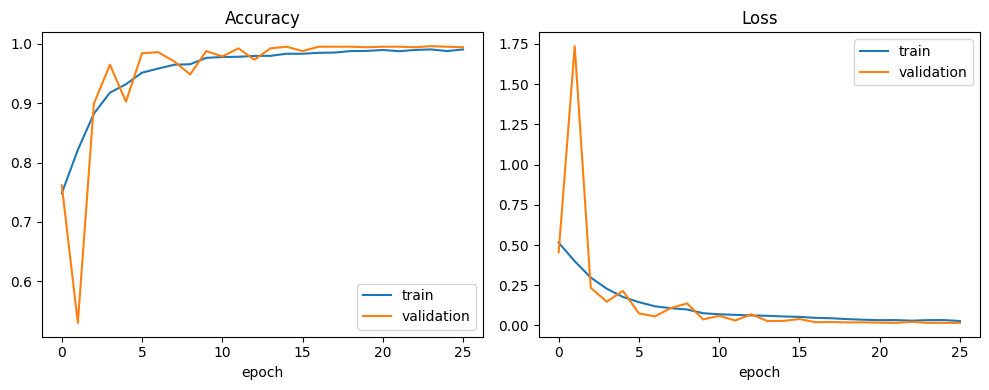

Validation accuracy: 0.995


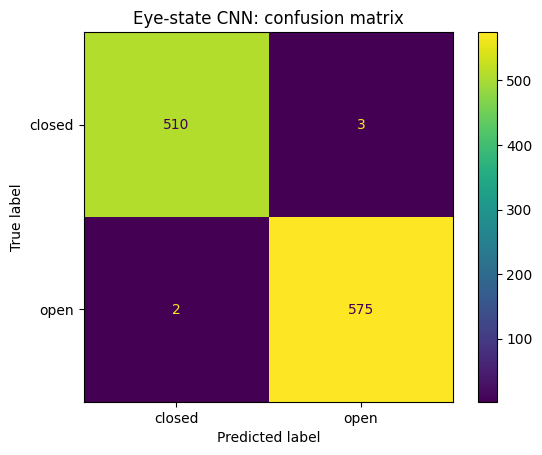

In [ ]:
#Loading the eye images and split them into 80% for training and 20% for validation
train_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset/eye",
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(64, 64),
    color_mode="grayscale",
    batch_size=32,
    label_mode="binary",
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset/eye",
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(64, 64),
    color_mode="grayscale",
    batch_size=32,
    label_mode="binary",
    shuffle=True
)

class_names = train_ds.class_names

#CNN model architecture
cnn = models.Sequential([
    layers.Input(shape=(64, 64, 1)),
    layers.Rescaling(1/255),
    layers.Conv2D(16, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(momentum=0.9),
    layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])

cnn.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
cnn.summary()

early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, min_delta=0.002, restore_best_weights=True)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_delta=0.002, min_lr=0.00001)

history = cnn.fit(train_ds, validation_data=val_ds, epochs=30, callbacks=[early_stop, reduce_lr])

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.title("Accuracy")
plt.xlabel("epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Loss")
plt.xlabel("epoch")
plt.legend()

plt.tight_layout()
plt.show()

y_true, y_pred = [], []

for x, y in val_ds:
    y_true += list(y.numpy().ravel().astype(int))
    y_pred += list((cnn.predict(x, verbose=0).ravel() > 0.5).astype(int))

print(f"Validation accuracy: {np.mean(np.array(y_true) == np.array(y_pred)):.3f}")

ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, labels=[0, 1]), display_labels=class_names).plot()

plt.title("Eye-state CNN: confusion matrix")
plt.show()

In [ ]:
eye_cnn = cnn

**Mouth CNN Model**

Found 6114 files belonging to 2 classes.
Using 4892 files for training.
Found 6114 files belonging to 2 classes.
Using 1222 files for validation.


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_6 (Rescaling)         │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 62, 62, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 31, 31, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 29, 29, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,777 (108.50 KB)

 Trainable params: 27,649 (108.00 KB)

 Non-trainable params: 128 (512.00 B)

Epoch 1/30
153/153 ━━━━━━━━━━━━━━━━━━━━ 21s 121ms/step - accuracy: 0.8275 - loss: 0.4100 - val_accuracy: 0.8470 - val_loss: 0.3888 - learning_rate: 0.0010
Epoch 2/30
153/153 ━━━━━━━━━━━━━━━━━━━━ 20s 130ms/step - accuracy: 0.9015 - loss: 0.2591 - val_accuracy: 0.9157 - val_loss: 0.2168 - learning_rate: 0.0010
Epoch 3/30
153/153 ━━━━━━━━━━━━━━━━━━━━ 18s 120ms/step - accuracy: 0.9211 - loss: 0.2152 - val_accuracy: 0.9354 - val_loss: 0.1677 - learning_rate: 0.0010
Epoch 4/30
153/153 ━━━━━━━━━━━━━━━━━━━━ 20s 130ms/step - accuracy: 0.9362 - loss: 0.1797 - val_accuracy: 0.9239 - val_loss: 0.1791 - learning_rate: 0.0010
Epoch 5/30
153/153 ━━━━━━━━━━━━━━━━━━━━ 19s 121ms/step - accuracy: 0.9405 - loss: 0.1703 - val_accuracy: 0.9574 - val_loss: 0.1262 - learning_rate: 0.0010
Epoch 6/30
153/153 ━━━━━━━━━━━━━━━━━━━━ 18s 120ms/step - accuracy: 0.9473 - loss: 0.1537 - val_accuracy: 0.9476 - val_loss: 0.1304 - learning_rate: 0.0010
Epoch 7/30
153/153 ━━━━━━━━━━━━━━━━━━━━ 21s 120ms/step - accuracy: 0.9

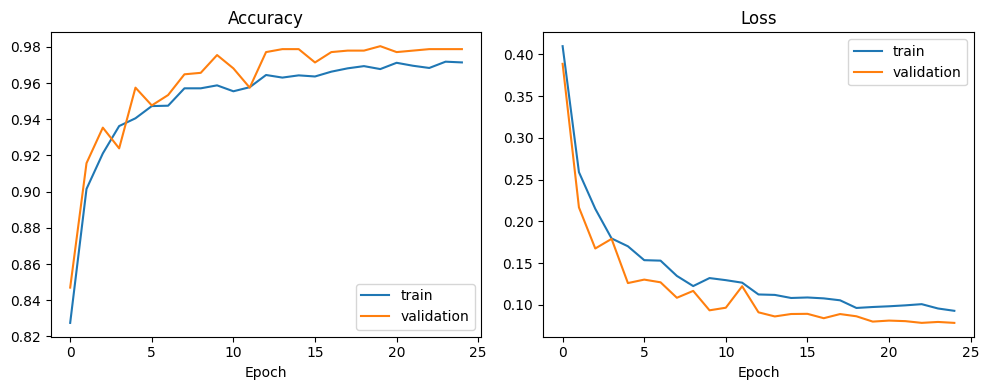

Validation accuracy: 0.98


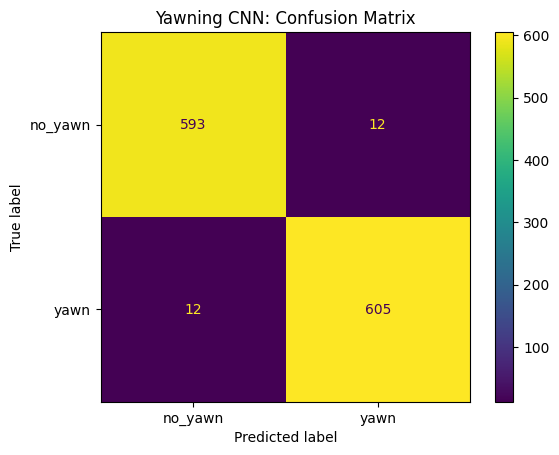

In [ ]:
 #Loading the mouth images and split them into 80% for training and 20% for validation
train_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset/mouth",
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(64, 64),
    color_mode="grayscale",
    batch_size=32,
    label_mode="binary",
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset/mouth",
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(64, 64),
    color_mode="grayscale",
    batch_size=32,
    label_mode="binary",
    shuffle=True
)

class_names = train_ds.class_names
#CNN model architecture
cnn = models.Sequential([
    layers.Input(shape=(64, 64, 1)),
    layers.Rescaling(1/255),
    layers.Conv2D(16, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(momentum=0.9),
    layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])

cnn.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

cnn.summary()

early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, min_delta=0.002, restore_best_weights=True)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_delta=0.002, min_lr=0.00001)

history = cnn.fit(train_ds, validation_data=val_ds, epochs=30, callbacks=[early_stop, reduce_lr])

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

y_true, y_pred = [], []

for x, y in val_ds:
    y_true.extend(y.numpy().ravel().astype(int))
    y_pred.extend(
        (cnn.predict(x, verbose=0).ravel() >= 0.5).astype(int)
    )

print("Validation accuracy:", round(np.mean(np.array(y_true) == np.array(y_pred)), 3))

ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, labels=[0, 1]), display_labels=class_names).plot()

plt.title("Yawning CNN: Confusion Matrix")
plt.show()

In [ ]:
mouth_cnn = cnn

**`Fuzzy System`**

In [ ]:
!pip install scikit-fuzzy

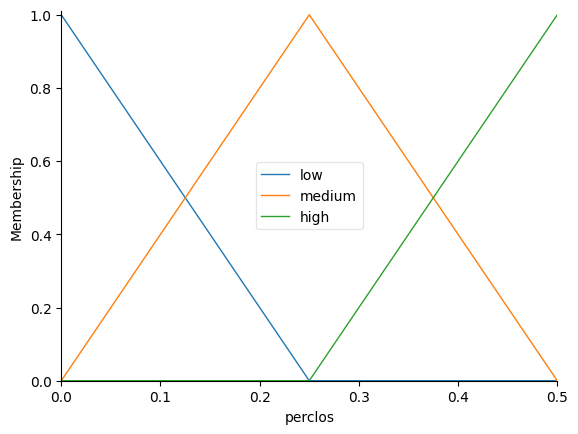

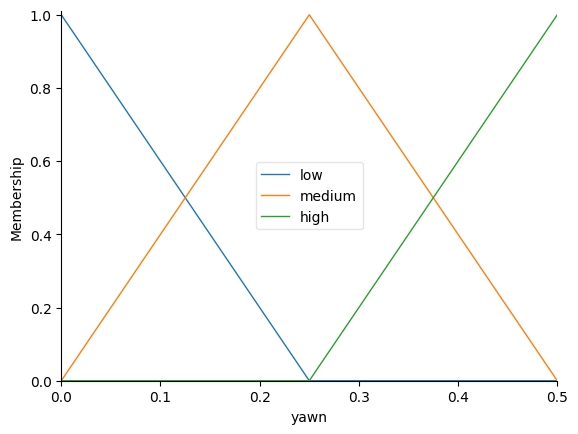

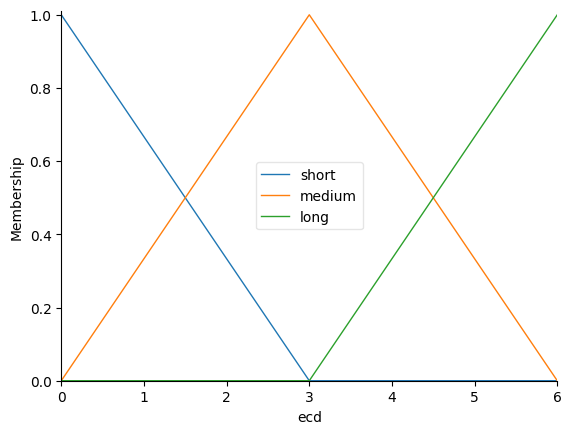

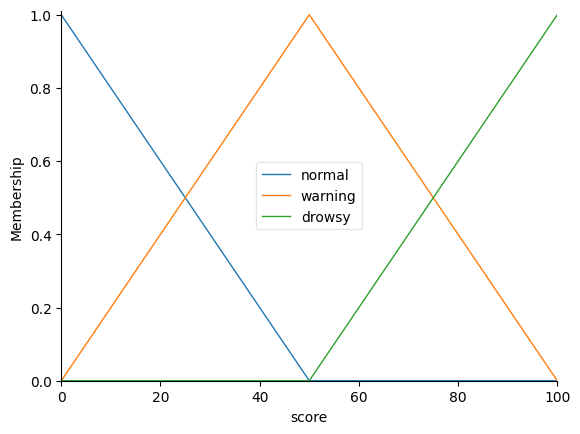

In [ ]:
from skfuzzy import control as ctrl

#Antecedents
perclos = ctrl.Antecedent(np.arange(0, 0.51, 0.01), "perclos")   #perclos = fraction of images in which the eye_cnn says the eyes are closed (0.5 = closed in half of the frames)
yawn = ctrl.Antecedent(np.arange(0, 0.51, 0.01), "yawn")         #yawn = fraction of images in which the mouth_cnn says the driver is yawning (0.5 = yawning in half of the frames)
ecd = ctrl.Antecedent(np.arange(0, 6.1, 0.1), "ecd")             #ecd = longest run of closed-eye frames in a row
#Consequent
score = ctrl.Consequent(np.arange(0, 101, 1), "score")           #drowsiness score in the range 0-100

perclos.automf(3, names=["low", "medium", "high"])
yawn.automf(3, names=["low", "medium", "high"])
ecd.automf(3, names=["short", "medium", "long"])
score.automf(3, names=["normal", "warning", "drowsy"])

#Fuzzy IF-THEN rules
rules = [
    ctrl.Rule(perclos["high"] | yawn["high"] | ecd["long"], score["drowsy"]),
    ctrl.Rule(perclos["medium"] | ecd["medium"], score["warning"]),
    ctrl.Rule(yawn["medium"] & perclos["low"], score["warning"]),
    ctrl.Rule(perclos["low"] & yawn["low"] & ecd["short"], score["normal"]),
]
fuzzy = ctrl.ControlSystemSimulation(ctrl.ControlSystem(rules))

def fuzzy_decision(p, y, e):
    fuzzy.input["perclos"] = min(p, 0.5)
    fuzzy.input["yawn"] = min(y, 0.5)
    fuzzy.input["ecd"] = min(e, 6)
    fuzzy.compute()
    s = fuzzy.output["score"]
    return s, ("normal" if s < 45 else "warning" if s < 55 else "drowsy")

def crisp_decision(p, y, e):
    if p >= 0.30 or y >= 0.20 or e >= 3:
        return "drowsy"
    if p >= 0.15 or y >= 0.10 or e >= 2:
        return "warning"
    return "normal"

perclos.view()
yawn.view()
ecd.view()
score.view()

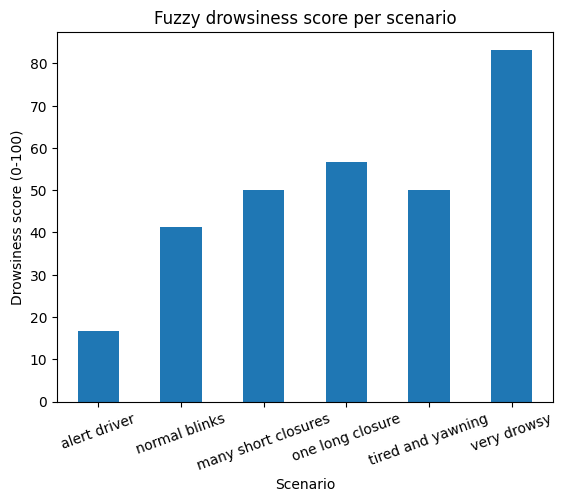

,Scenario,PERCLOS,Yawn share,ECD (frames),Fuzzy score,Fuzzy state,Crisp state
0,alert driver,0.00,0.00,0,16.7,normal,normal
1,normal blinks,0.10,0.05,1,41.2,normal,normal
2,many short closures,0.25,0.00,1,50.0,warning,warning
3,one long closure,0.25,0.00,5,56.7,drowsy,drowsy
4,tired and yawning,0.20,0.25,2,50.0,warning,drowsy
5,very drowsy,0.70,0.35,14,83.3,drowsy,drowsy


In [ ]:
import pandas as pd
random.seed(42)
open_eyes = glob.glob("dataset/eye/open/*");    closed_eyes = glob.glob("dataset/eye/closed/*")
yawn_imgs = glob.glob("dataset/mouth/yawn/*");  no_yawn_imgs = glob.glob("dataset/mouth/no_yawn/*")

def load(files):
    return np.array([tf.keras.utils.img_to_array(
        tf.keras.utils.load_img(f, color_mode="grayscale", target_size=(64, 64),
                                interpolation="bilinear")) for f in files])

def longest_streak(closed):
    best, run = 0, 0
    for c in closed:
        run = run + 1 if c else 0
        best = max(best, run)
    return best

def check_driver(name, eye_pattern, n_yawn, n=20):
    eyes = [random.choice(closed_eyes if e else open_eyes) for e in eye_pattern]
    mouths = random.sample(yawn_imgs, n_yawn) + random.sample(no_yawn_imgs, n - n_yawn)

    closed = (eye_cnn.predict(load(eyes), verbose=0) < 0.5).ravel()        # eye CNN: P(open) < 0.5 -> closed
    yawning = (mouth_cnn.predict(load(mouths), verbose=0) > 0.5).ravel()   # mouth_cnn: P(yawn) > 0.5 -> yawning

    p = closed.mean()                 # PERCLOS
    y = yawning.mean()                # yawn share
    e = longest_streak(closed)        # eye closure duration measured in frames
    s, state = fuzzy_decision(p, y, e)
    return [name, round(p, 2), round(y, 2), e, round(s, 1), state, crisp_decision(p, y, e)]

rows = [
    check_driver("alert driver",        [0] * 20, 0),
    check_driver("normal blinks",       [0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0], 0),
    check_driver("many short closures", [1,0,0] * 6 + [0,0], 0),
    check_driver("one long closure",    [0] * 15 + [1] * 5, 0),
    check_driver("tired and yawning",   [0,0,0,1,1,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0], 5),
    check_driver("very drowsy",         [0] * 6 + [1] * 14, 8),
]

results = pd.DataFrame(rows, columns=["Scenario", "PERCLOS", "Yawn share", "ECD (frames)",
                                      "Fuzzy score", "Fuzzy state", "Crisp state"])

results.plot.bar(x="Scenario", y="Fuzzy score", legend=False, rot=20)
plt.ylabel("Drowsiness score (0-100)"); plt.title("Fuzzy drowsiness score per scenario")
plt.show()

results

In [ ]:
#Alerting the driver
def alert(state):
    if state == "normal":
        print("Driver is alert. No action needed.")
    elif state == "warning":
        print("WARNING: Signs of fatigue detected. Please stay alert.")
    else:
        print("DROWSY! WAKE UP! Please rest.")

for i in range(len(results)):
    print(results["Scenario"][i], "->", end=" ")
    alert(results["Fuzzy state"][i])

alert driver -> Driver is alert. No action needed.
normal blinks -> Driver is alert. No action needed.
many short closures -> WARNING: Signs of fatigue detected. Please stay alert.
one long closure -> DROWSY! WAKE UP! Please rest.
tired and yawning -> WARNING: Signs of fatigue detected. Please stay alert.
very drowsy -> DROWSY! WAKE UP! Please rest.


In [ ]:
eye_cnn.save("eye_cnn.keras")
mouth_cnn.save("mouth_cnn.keras")
results.to_csv("results.csv", index=False)

from google.colab import files
files.download("eye_cnn.keras")
files.download("mouth_cnn.keras")
files.download("results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>